# WP12 — Bağımsız kullanıcı PowerShell testine devir
Bu notebook gerçek Codex ölçümünü ve bekleyen teslim kaydını gösterir. Kullanıcı betiğini, yerel LLM'yi veya19×3 senaryoyu çalıştırmaz.

,Zaman,Boş RAM GiB,Boş VRAM MiB,AppContainer
0,2026-11-08T03:42:44.085060+03:00,0.886578,1633,True


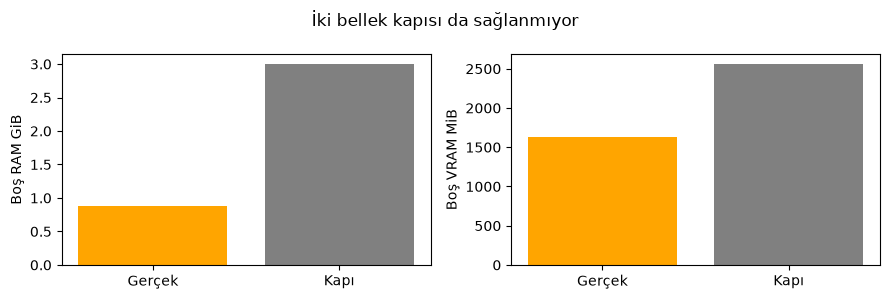

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/user_powershell_smoke_v1'
r=json.loads((Q/'codex_measurement.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Zaman':r['captured_at'],'Boş RAM GiB':r['RAM']['available']/2**30,'Boş VRAM MiB':r['GPU']['free_MiB'],'AppContainer':r['process_token']['is_appcontainer']}]))
fig,axs=plt.subplots(1,2,figsize=(9,3))
axs[0].bar(['Gerçek','Kapı'],[r['RAM']['available']/2**30,3],color=['orange','grey']);axs[0].set_ylabel('Boş RAM GiB')
axs[1].bar(['Gerçek','Kapı'],[r['GPU']['free_MiB'],2560],color=['orange','grey']);axs[1].set_ylabel('Boş VRAM MiB')
fig.suptitle('İki bellek kapısı da sağlanmıyor');fig.tight_layout();F=ROOT/'reports/figures/WP12/user_powershell_smoke_v1';F.mkdir(parents=True,exist_ok=True);fig.savefig(F/'memory_gates.png',dpi=150);plt.show()

**Yorum:**3GiB RAM/2,5GiB VRAM tabanı aynen korunuyor. Ölçüm modelin bellek tüketimi değildir; hangi süreçlerin kullandığına ilişkin çıkarım yapılmadı.

In [2]:
display(pd.DataFrame([r['API_version']]))
display(pd.DataFrame([json.loads((Q/'external_output_review_record.json').read_text(encoding='utf-8'))]).T)
print((Q/'powershell_parse_check.txt').read_text(encoding='utf-8'))

PowerShell AST parse: 0 errors; script NOT executed



,error_type,error
0,URLError,<urlopen error [WinError 10013] An attempt was...


,0
status,AWAITING_USER_POWERSHELL_OUTPUT
actual_user_output_received,False
smoke_technical_result,None
source_explanation_quality,NOT_TESTED
reported_in_PDF,None
predicted_by_GNN,"{'status': 'NOT_REQUESTED_IN_WP12', 'artifact_..."
human_semantic_review,NOT_PERFORMED_NO_LLM_EXPLANATION
automatic_release,False
Codex_inference_calls,0
real_scenario_repeats,0


**Yorum:**10013 izin reddi, Qwen model arızasının kanıtı değildir. AppContainer dışındaki gerçek kullanıcı testi ayrı kanıt olacaktır. Betik yalnız parse edildi; kullanıcı çıktısı yoktur. Bekleyen inceleme kaydı LLM başarısı veya insan semantik onayı değildir.

In [3]:
for n in ['test_wp12_user_smoke_review.py.log','test_wp12_llm_preflight.py.log','test_wp12_llm_contract.py.log']:
 print(n);print((Q/n).read_text(encoding='utf-8'))

test_wp12_user_smoke_review.py.log
test_appcontainer_inference_rejected (test_wp12_user_smoke_review.ExternalReviewTests.test_appcontainer_inference_rejected) ... ok
test_below_three_GiB_rejected (test_wp12_user_smoke_review.ExternalReviewTests.test_below_three_GiB_rejected) ... ok
test_changed_model_rejected (test_wp12_user_smoke_review.ExternalReviewTests.test_changed_model_rejected) ... ok
test_changed_seed_rejected (test_wp12_user_smoke_review.ExternalReviewTests.test_changed_seed_rejected) ... ok
test_changed_threshold_rejected (test_wp12_user_smoke_review.ExternalReviewTests.test_changed_threshold_rejected) ... ok
test_consistent_technical_fixture_does_not_auto_release (test_wp12_user_smoke_review.ExternalReviewTests.test_consistent_technical_fixture_does_not_auto_release) ... ok
test_duplicate_echo_keys_rejected (test_wp12_user_smoke_review.ExternalReviewTests.test_duplicate_echo_keys_rejected) ... ok
test_multiple_calls_rejected (test_wp12_user_smoke_review.ExternalReviewTests.

**Yorum:**42 offline test teknik kapıları sınar. Test fixture'ları gerçek kullanıcı/model çıktısı değildir.19 senaryo çalıştırılmadı. Gerçek dosya geldiğinde ayrı inceleme kaydı üretilecek; ham kayıt değişmeyecek. WP13 başlamadan burada durulur.